# Detecting Suspected Insider Trading on Polymarket via Account Trust Scores
**Big Data Analytics – Final Project, Group 4** · Muhammet Yildiz, Peyman Aparviz, Orlando Poensgen
**Deliverable:** 2nd delivery (intermediate status)

## Status of this delivery
| Layer | Status | What is in this notebook |
|---|---|---|
| 1. Data Source | working | Gamma API (markets), Data API (trades), Etherscan/Polygonscan (wallet age) |
| 2. Data Storage | working | raw JSON -> MongoDB, cleaned -> Parquet |
| 3. Analysis | first version | data quality checks, descriptive stats, first Spark aggregation per wallet |
| 4. Output | first version | first plots (volume, crowd-price calibration) |
| ML / suspicion score | planned | see "Next steps" at the end |

**Research question:** Can suspected informed trading be detected on Polymarket, i.e. are there wallets that systematically enter *against the crowd price* early and win?

## 0. Setup & libraries

In [ ]:
# pip install requests pymongo pandas pyarrow pyspark matplotlib
import os, time, json, requests, datetime as dt
import pandas as pd
import matplotlib.pyplot as plt
from importlib.metadata import version

# Documentation requirement: list libraries with versions
for lib in ["requests", "pymongo", "pandas", "pyarrow", "pyspark", "matplotlib"]:
    try:
        print(f"{lib:12s} {version(lib)}")
    except Exception as e:
        print(f"{lib:12s} NOT INSTALLED")

requests     2.34.2
pymongo      4.20.1
pandas       3.1.1
pyarrow      26.0.1
pyspark      4.3.0
matplotlib   3.11.2


In [ ]:
# ---- Configuration -------------------------------------------------
GAMMA_URL = "https://gamma-api.polymarket.com"
DATA_URL  = "https://data-api.polymarket.com"      # we call the /v2/... routes (v1 returns 410 Gone / retires Nov 2, 2026)
ETHERSCAN_V2 = "https://api.etherscan.io/v2/api"   # Polygonscan is served via Etherscan API V2 (chainid=137)
ETHERSCAN_KEY = os.getenv("ETHERSCAN_API_KEY", "")  # DO NOT hardcode your key

MONGO_URI = os.getenv("MONGO_URI", "mongodb://localhost:27017")
DB_NAME   = "polymarket"

N_MARKETS = 500          # start small, scale up later
N_SAMPLE_MARKETS = 20    # markets for which we pull trades in this delivery
MAX_TRADES_PER_MARKET = 200  # cap per market, keeps API calls and runtime small
DATA_DIR  = "data"; os.makedirs(DATA_DIR, exist_ok=True)

## 1. Data Source Layer
### 1.1 Source overview
| # | Source | Type | Content | Key fields |
|---|---|---|---|---|
| 1 | Polymarket Gamma API | REST / JSON | markets, creation dates, resolution | `conditionId`, `question`, `outcomes`, `outcomePrices`, `volume`, `createdAt`, `endDate`, `closed` |
| 2 | Polymarket Data API | REST / JSON | trades per market / wallet | `proxy_wallet`, `side`, `price`, `size`, `timestamp`, `outcome_index`, `condition_id` |
| 3 | Polygonscan (Etherscan V2, chain 137) | REST / JSON | first on-chain tx of a wallet = wallet age | `timeStamp`, `from`, `to` |

Note: `outcomes` and `outcomePrices` come as JSON-encoded strings. A resolved market has prices like `["1","0"]`; the index of the `1` is the winning outcome.

In [ ]:
def get_json(url, params=None, retries=4, pause=1.0):
    """GET with retry/backoff. Only retries what can succeed later (429 / 5xx / network errors);
    other 4xx (e.g. 400 bad params, 410 endpoint gone) are permanent, so we fail immediately."""
    for i in range(retries):
        try:
            r = requests.get(url, params=params, timeout=30)
            if r.status_code == 429 or r.status_code >= 500:
                # respect the server's Retry-After header if present, otherwise exponential backoff
                wait = float(r.headers.get("Retry-After", pause * 2 ** i))
                print(f"  {r.status_code}, waiting {wait:.0f}s")
                time.sleep(wait); continue
            r.raise_for_status()          # permanent errors raise here, no pointless retries
            return r.json()
        except requests.HTTPError as e:
            print("  permanent error:", e); return None
        except requests.RequestException as e:   # timeouts, connection problems
            print(f"  retry {i+1}/{retries}: {e}")
            time.sleep(pause * 2 ** i)
    return None

def fetch_closed_markets(n, page=100):
    """Gamma API still uses limit/offset pagination. Sorted by volume so we get liquid markets first."""
    out, offset = [], 0
    while len(out) < n:
        batch = get_json(f"{GAMMA_URL}/markets",
                         {"closed": "true", "limit": page, "offset": offset,
                          "order": "volume", "ascending": "false"})
        if not batch: break          # empty page or error -> stop
        out += batch; offset += page
        time.sleep(0.2)              # be polite to the API
    return out[:n]

markets_raw = fetch_closed_markets(N_MARKETS)
print(len(markets_raw), "markets fetched")
# look at one raw document to understand the structure (truncated)
print(json.dumps(markets_raw[0], indent=2)[:1500] if markets_raw else "no data")

500 markets fetched
{
  "id": "3914648",
  "question": "Gwangju FC vs. Jeju SK FC: Jeju SK FC O/U 0.5",
  "conditionId": "0xc7528fbf34f6690317786bb55ba14f6af6a388721f34cbecedaf0d1254e34e8e",
  "slug": "kor-gwa-jej-2026-09-09-team-total-away-0pt5",
  "resolutionSource": "https://www.kleague.com/",
  "endDate": "2026-09-09T10:30:00Z",
  "startDate": "2026-08-26T22:00:40Z",
  "image": "https://polymarket-upload.s3.us-east-2.amazonaws.com/k-league-87b53492f4.png",
  "icon": "https://polymarket-upload.s3.us-east-2.amazonaws.com/k-league-87b53492f4.png",
  "description": "In the upcoming K-League game between Gwangju FC and Jeju SK FC, scheduled for September 9 at 6:30 AM ET: This market will resolve to \"Over\" if Jeju SK FC score 1 or more goals within the first 90 minutes of regular play plus stoppage time. If Jeju SK FC score less than 1 goals within the first 90 minutes of regular play plus stoppage time, this market will resolve to \"Under\". This market is based solely on Jeju SK FC's

### 1.2 Trades per market (Data API v2)
v2 differences to v1 (that caused the `410 Gone`): route `/v2/trades`, filter `condition=` (not `market=`), **cursor pagination** (no `offset`), responses wrapped in `{data, pagination}` and fields in `snake_case` (`proxy_wallet`, `condition_id`, ...).
Note: trades come newest-first, so a cap per market keeps the *latest* trades (closest to resolution). For the final analysis we need the full history.

In [ ]:
def fetch_trades(condition_id, max_rows=MAX_TRADES_PER_MARKET, page=200):
    """Walk /v2/trades for one market by following pagination.next_cursor until max_rows is reached."""
    out, cursor = [], None
    while len(out) < max_rows:
        # the same filters must be re-sent on every page; the cursor only carries the position
        params = {"condition": condition_id, "limit": page}
        if cursor: params["cursor"] = cursor
        resp = get_json(f"{DATA_URL}/v2/trades", params)
        if not resp: break
        out += resp.get("data", [])
        pg = resp.get("pagination", {})
        if not pg.get("has_more"): break          # last page reached
        cursor = pg.get("next_cursor")
        time.sleep(0.2)
    return out[:max_rows]

trades_raw = []
for m in markets_raw[:N_SAMPLE_MARKETS]:
    cid = m.get("conditionId")
    if not cid: continue                           # some markets have no condition id
    t = fetch_trades(cid)
    trades_raw += t
    print(f"{m.get('question','?')[:60]:60s} {len(t):5d} trades")
print("total trades:", len(trades_raw))
if trades_raw: print(json.dumps(trades_raw[0], indent=2)[:800])   # inspect the v2 row structure

Gwangju FC vs. Jeju SK FC: Jeju SK FC O/U 0.5                    9 trades
Kings vs. Mavericks: 1Q O/U 51.5                                11 trades
Games Total: O/U 2.5                                             7 trades
Ethereum above 2,275 on April 21, 3PM ET?                        4 trades
Map Handicap: Invicta (-1.5) vs Evo Novo (+1.5)                  7 trades
Hassani vs. Nolan: Match O/U 22.5                                5 trades
Will the highest temperature in Milan be 29°C on September 2     8 trades
Bradford City AFC vs. Marine AFC: Marine AFC 1st Half O/U 0.    16 trades
Exact Score: Albacete Balompié 0 - 3 CD Eldense?                 4 trades
Exact Score: FC Koper 0 - 3 NK Maribor?                          4 trades
Exact Score: Sheffield Wednesday FC 0 - 3 Cambridge United F     4 trades
Racing Club de Lens vs. Como 1907: Both Teams to Score in Fi     3 trades
Exact Score: Al Ittihad Saudi Club 1 - 1 Al Qadisiyah Saudi      3 trades
Exact Score: US Cremonese 0 - 1 Como 1

### 1.3 Wallet age (2nd, independent source)
Wallet age = timestamp of the first on-chain transaction. Requires a free API key (set `ETHERSCAN_API_KEY`).

In [ ]:
def wallet_first_tx(address):
    """Ask for exactly ONE transaction sorted ascending = the wallet's first tx."""
    if not ETHERSCAN_KEY: return None              # no key -> skip this source gracefully
    res = get_json(ETHERSCAN_V2, {"chainid": 137, "module": "account", "action": "txlist",
                                  "address": address, "startblock": 0, "endblock": 99999999,
                                  "page": 1, "offset": 1, "sort": "asc", "apikey": ETHERSCAN_KEY})
    if res and res.get("status") == "1" and res["result"]:
        return {"address": address, "first_tx_ts": int(res["result"][0]["timeStamp"])}
    return {"address": address, "first_tx_ts": None}

# unique wallets that appear in our trades (set removes duplicates)
wallets = list({t["proxy_wallet"] for t in trades_raw if t.get("proxy_wallet")})
print(len(wallets), "unique wallets in sample")

wallet_age_raw = []
for w in wallets[:50]:                  # free tier is rate limited (~5 req/s), keep it small for now
    r = wallet_first_tx(w)
    if r: wallet_age_raw.append(r)
    time.sleep(0.25)
print(len(wallet_age_raw), "wallet ages fetched")

61 unique wallets in sample
0 wallet ages fetched


## 2. Data Storage Layer
**Design:** raw API responses are stored unchanged in **MongoDB** (schema-flexible, JSON-native, re-processable). Cleaned and merged data goes to **Parquet** (columnar, efficient for Spark).

| Collection | Content | Unique key |
|---|---|---|
| `markets_raw` | Gamma API documents | `conditionId` |
| `trades_raw` | Data API trades | `transaction_hash` + `token_id` + `proxy_wallet` |
| `wallets_raw` | first-tx info | `address` |

In [ ]:
from pymongo import MongoClient, UpdateOne

# short timeout so the notebook does not hang if MongoDB is not running
client = MongoClient(MONGO_URI, serverSelectionTimeoutMS=3000)
db = client[DB_NAME]

def upsert(coll, docs, key_fn):
    """Idempotent insert: re-running the notebook updates existing docs instead of duplicating them."""
    ops = [UpdateOne(key_fn(d), {"$set": d}, upsert=True) for d in docs]
    if ops: coll.bulk_write(ops, ordered=False)

try:
    client.admin.command("ping")
    upsert(db.markets_raw, markets_raw, lambda d: {"conditionId": d.get("conditionId")})
    upsert(db.trades_raw, trades_raw,
           lambda d: {"transaction_hash": d.get("transaction_hash"), "token_id": d.get("token_id"),
                      "proxy_wallet": d.get("proxy_wallet")})
    upsert(db.wallets_raw, wallet_age_raw, lambda d: {"address": d["address"]})
    # indexes speed up the typical access paths: trades per market over time, and trades per wallet
    db.trades_raw.create_index([("condition_id", 1), ("timestamp", 1)])
    db.trades_raw.create_index("proxy_wallet")
    print({c: db[c].count_documents({}) for c in ["markets_raw", "trades_raw", "wallets_raw"]})
except Exception as e:
    print("MongoDB not reachable:", e)
    print("Start it with: docker run -d -p 27017:27017 --name mongo mongo:7")

MongoDB not reachable: localhost:27017: [Errno 111] Connection refused (configured timeouts: socketTimeoutMS: 20000.0ms, connectTimeoutMS: 20000.0ms), Timeout: 3.0s, Topology Description: <TopologyDescription id: 6aff7f8564a1923406546d91, topology_type: Unknown, servers: [<ServerDescription ('localhost', 27017) server_type: Unknown, rtt: None, error=AutoReconnect('localhost:27017: [Errno 111] Connection refused (configured timeouts: socketTimeoutMS: 20000.0ms, connectTimeoutMS: 20000.0ms)')>]>
Start it with: docker run -d -p 27017:27017 --name mongo mongo:7


In [ ]:
# MongoDB aggregation pipeline (runs inside the DB): trades and USD volume per wallet, top 5
# size is in shares, price in USDC/share -> size*price = USD
try:
    pipe = [{"$group": {"_id": "$proxy_wallet", "n": {"$sum": 1}, "usd": {"$sum": {"$multiply": ["$size", "$price"]}}}},
            {"$sort": {"usd": -1}}, {"$limit": 5}]
    for d in db.trades_raw.aggregate(pipe): print(d)
except Exception as e:
    print(e)

localhost:27017: [Errno 111] Connection refused (configured timeouts: socketTimeoutMS: 20000.0ms, connectTimeoutMS: 20000.0ms), Timeout: 3.0s, Topology Description: <TopologyDescription id: 6aff7f8564a1923406546d91, topology_type: Unknown, servers: [<ServerDescription ('localhost', 27017) server_type: Unknown, rtt: None, error=AutoReconnect('localhost:27017: [Errno 111] Connection refused (configured timeouts: socketTimeoutMS: 20000.0ms, connectTimeoutMS: 20000.0ms)')>]>


## 3. Cleaning & data quality
Checks: completeness, duplicates, ambiguous resolutions (prices not 1/0), crypto-price markets (excluded), timestamps.

In [ ]:
mk = pd.DataFrame(markets_raw)
tr = pd.DataFrame(trades_raw)
print("markets:", mk.shape, "| trades:", tr.shape)
print("\nMissing values markets (top 10):\n", mk.isna().mean().sort_values(ascending=False).head(10))
print("\nMissing values trades:\n", tr.isna().mean().sort_values(ascending=False).head(10))
print("\nDuplicate trades:", tr.duplicated(subset=["transaction_hash", "token_id", "proxy_wallet"]).sum() if len(tr) else 0)

markets: (500, 128) | trades: (128, 19)

Missing values markets (top 10):
 marketType                  0.998
marketMakerAddress          0.998
sentDiscord                 0.998
twitterCardLocation         0.998
marketGroup                 0.998
twitterCardLastRefreshed    0.998
creator                     0.998
fpmmLive                    0.998
category                    0.998
fee                         0.998
dtype: float64

Missing values trades:
 proxy_wallet    0.0
side            0.0
token_id        0.0
condition_id    0.0
size            0.0
price           0.0
timestamp       0.0
title           0.0
slug            0.0
icon            0.0
dtype: float64

Duplicate trades: 0


In [ ]:
def parse_list(x):
    """Gamma returns lists as JSON strings, e.g. '["1","0"]' -> real list."""
    if isinstance(x, list): return x
    try: return json.loads(x)
    except Exception: return None

def winner_index(row):
    """Index of the winning outcome: the one whose final price is exactly 1. Otherwise None."""
    p = parse_list(row.get("outcomePrices"))
    if not p: return None
    p = [float(v) for v in p]
    return p.index(1.0) if (max(p) == 1.0 and p.count(1.0) == 1) else None   # None = ambiguous / 50-50 / cancelled

mk["winner_idx"] = mk.apply(winner_index, axis=1)
mk["resolved_clean"] = mk["winner_idx"].notna()
print("Clearly resolved:", mk["resolved_clean"].mean().round(3))

# exclude crypto-price markets (short-term price bets, nobody can have "inside information")
# (rough regex, check what it catches and refine)
crypto_pat = r"(?i)\b(bitcoin|btc|ethereum|eth|solana|sol|xrp|crypto)\b.*\b(above|below|price|up or down|reach)\b"
mk["is_crypto_price"] = mk["question"].fillna("").str.contains(crypto_pat, regex=True)
print("Crypto-price markets:", mk["is_crypto_price"].sum())

mk_clean = mk[mk.resolved_clean & ~mk.is_crypto_price].copy()
mk_clean["conditionId"] = mk_clean["conditionId"].str.lower()   # normalise ids so joins with trades match
for c in ["createdAt", "endDate"]:
    if c in mk_clean: mk_clean[c] = pd.to_datetime(mk_clean[c], errors="coerce", utc=True)
mk_clean["volume"] = pd.to_numeric(mk_clean.get("volume"), errors="coerce")
print("Clean markets:", len(mk_clean))

Clearly resolved: 0.992
Crypto-price markets: 28
Clean markets: 468


/tmp/ipykernel_19174/4138516959.py:21: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  mk["is_crypto_price"] = mk["question"].fillna("").str.contains(crypto_pat, regex=True)


## 4. First descriptive statistics & visualisation

count       468.000000
mean       4160.840097
std       47488.525185
min           9.999500
25%          99.995518
50%         999.963149
75%         999.989575
max      999970.610198
Name: volume, dtype: float64


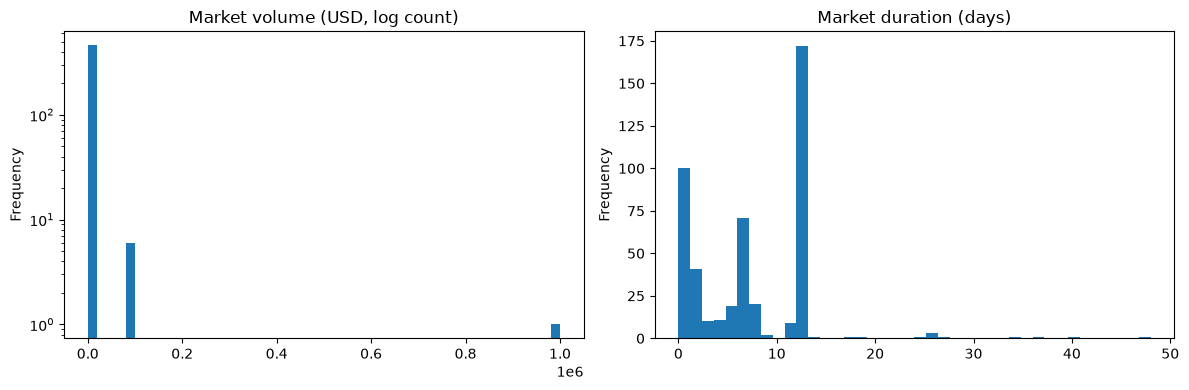

In [ ]:
print(mk_clean["volume"].describe())
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
mk_clean["volume"].plot.hist(bins=50, log=True, ax=ax[0], title="Market volume (USD, log count)")
if "createdAt" in mk_clean:
    (mk_clean["endDate"] - mk_clean["createdAt"]).dt.days.clip(0, 365).plot.hist(bins=40, ax=ax[1], title="Market duration (days)")
plt.tight_layout(); plt.show()

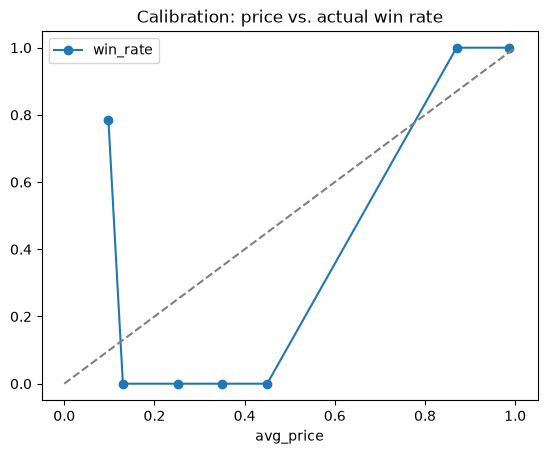

            avg_price  win_rate   n
bin                                
(0.0, 0.1]   0.097857  0.785714  14
(0.1, 0.2]   0.130000  0.000000   4
(0.2, 0.3]   0.251852  0.000000  27
(0.3, 0.4]   0.350000  0.000000   1
(0.4, 0.5]   0.450000  0.000000   4
(0.8, 0.9]   0.870000  1.000000   3
(0.9, 1.0]   0.986062  1.000000  64


In [ ]:
# Wisdom of the crowd: is the price paid by a trade a calibrated probability?
# (a perfectly calibrated crowd lies on the diagonal: shares bought at 0.2 win 20% of the time)
if len(tr):
    tr["condition_id"] = tr["condition_id"].str.lower()
    # inner join: keep only trades of markets that are cleanly resolved and not crypto
    t = tr.merge(mk_clean[["conditionId", "winner_idx"]], left_on="condition_id", right_on="conditionId", how="inner")
    t["price"] = pd.to_numeric(t["price"]); t["size"] = pd.to_numeric(t["size"])
    t = t[t["side"] == "BUY"]                      # only buys: a BUY of the winning outcome = a winning bet
    t["won"] = (t["outcome_index"] == t["winner_idx"]).astype(int)   # 1 if the bought outcome won
    t["bin"] = pd.cut(t["price"], bins=[i/10 for i in range(11)])
    cal = t.groupby("bin", observed=True).agg(avg_price=("price", "mean"), win_rate=("won", "mean"), n=("won", "size"))
    ax = cal.plot(x="avg_price", y="win_rate", marker="o", title="Calibration: price vs. actual win rate")
    ax.plot([0, 1], [0, 1], "--", color="gray"); plt.show(); print(cal)

## 5. Export cleaned data to Parquet

In [ ]:
if len(tr):
    t_out = t.copy()
    t_out["timestamp"] = pd.to_numeric(t_out["timestamp"])
    t_out[["proxy_wallet", "condition_id", "side", "price", "size", "timestamp", "outcome_index", "winner_idx", "won"]] \
        .to_parquet(f"{DATA_DIR}/trades_clean.parquet", index=False)
# Parquet cannot store nested list/dict columns -> drop them for the flat file (raw stays in MongoDB)
mk_clean.drop(columns=[c for c in mk_clean.columns if mk_clean[c].map(type).isin([list, dict]).any()]) \
        .to_parquet(f"{DATA_DIR}/markets_clean.parquet", index=False)
if wallet_age_raw: pd.DataFrame(wallet_age_raw).to_parquet(f"{DATA_DIR}/wallets.parquet", index=False)
print(os.listdir(DATA_DIR))

['markets_clean.parquet', 'trades_clean.parquet']


## 6. Processing Layer – first Spark job
Aggregate trades per wallet: number of trades, volume, win rate, average entry price on winning trades (**contrarian score = 1 - avg price of winners**).

In [ ]:
from pyspark.sql import SparkSession, functions as F
# local Spark session using all cores
spark = SparkSession.builder.appName("polymarket").master("local[*]").getOrCreate()

# read the cleaned Parquet file produced in step 5
st = spark.read.parquet(f"{DATA_DIR}/trades_clean.parquet")
# one row per wallet with first behavioural features (basis for the suspicion score later)
wallet_feat = (st.withColumn("usd", F.col("price") * F.col("size"))
    .groupBy("proxy_wallet")
    .agg(F.count("*").alias("n_trades"),
         F.countDistinct("condition_id").alias("n_markets"),
         F.sum("usd").alias("volume_usd"),
         F.avg("won").alias("win_rate"),
         # high value = wallet won while buying at low prices (= betting against the crowd)
         F.avg(F.when(F.col("won") == 1, 1 - F.col("price"))).alias("contrarian_entry"))
    .filter("n_trades >= 3"))          # ignore wallets with too few trades (too noisy)
wallet_feat.orderBy(F.desc("contrarian_entry")).show(10, truncate=False)
wallet_feat.write.mode("overwrite").parquet(f"{DATA_DIR}/wallet_features.parquet")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/20 00:00:30 WARN Utils: Your hostname, Fatih-HP, resolves to a loopback address: 127.0.1.1; using 192.168.0.192 instead (on interface wlo1)
26/11/20 00:00:30 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/home/fatih/Coding/bigdata/project/.venv/lib/python3.12/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/11/20 00:00:31 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


+------------------------------------------+--------+---------+------------------+------------------+---------------------+
|proxy_wallet                              |n_trades|n_markets|volume_usd        |win_rate          |contrarian_entry     |
+------------------------------------------+--------+---------+------------------+------------------+---------------------+
|0xc785252b25901a591e9d962e09f4342468444ef2|6       |1        |82.14000000000001 |1.0               |0.9                  |
|0x2a69660046d7acc4ab204d7cc5ba78b0776cd2f7|21      |2        |1596.21           |1.0               |0.02709523809523812  |
|0x660d5749a93fcfc81999a51cb661c495923f3aa6|3       |1        |98.28975          |1.0               |0.025000000000000022 |
|0x2d62575f0f91f0c031b9168f865dd43ae37f0a41|3       |3        |1471.0            |1.0               |0.01933333333333335  |
|0x821dab0565ebf5b327f51db06223fdcfe01acf16|9       |5        |1322.4899770299999|0.4444444444444444|0.007000000000000006 |
|0x05240

## 7. Big Data criteria (draft – to be finalised)
| V | Implication for our project |
|---|---|
| Volume | Polymarket has many thousands of markets and millions of trades; we start with a sample and scale up |
| Velocity | Trades arrive continuously; currently batch, streaming would be possible via the WebSocket feed |
| Variety | JSON from 3 APIs, nested/stringified fields, on-chain data |
| Veracity | ambiguous resolutions, multi-wallet users, wash trading, proxy wallets |
| Value | detecting informed trading and measuring crowd accuracy |

The four layers map to: APIs -> MongoDB/Parquet -> Spark/ML -> plots & story.

## 8. Next steps (until final delivery)
- [ ] Scale up markets and trades, run in Spark on the full dataset
- [ ] Join wallet age (Polygonscan) with wallet features; add timing-before-resolution
- [ ] Feature set: account age, volume, concentration, contrarian entry, repetition per category
- [ ] ML: anomaly detection (e.g. Isolation Forest, Spark MLlib) -> suspicion score and ranking
- [ ] Visuals: suspect ranking, contrarian-entry vs payout, timing chart; story
- [ ] Finalize Big Data Vs section and documentation (versions, sources, setup)